# M1b: pseudobulk differential expression

Contract: `audit/contracts/M1b_de.md`. Python: `src/m1b_de.py`; DESeq2 + qvalue: `R/m1b_deseq2.R` (tested in `tests/test_m1b.py`).
This notebook only reads their output files and shows them. **DE** = q < 0.05 and |log2FC| > 1 (unshrunk log2FC, treatment vs control).
No verdicts here: robustness and negative-control checks (R1–R3, N1) are computed in M2.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.m0_qc import ribosomal_mask

pd.set_option("display.width", 160, "display.max_columns", 20)
PROC = ROOT / "data/processed"
FILES = ["m1b_de.csv", "m1b_runs.csv", "m1b_fits.csv"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110})

de = pd.read_csv(PROC / "m1b_de.csv")
runs = pd.read_csv(PROC / "m1b_runs.csv", usecols=["run", "cell_type", "gene", "de", "pvalue", "cooks_flag"])
fits = pd.read_csv(PROC / "m1b_fits.csv")
CELL_TYPES = sorted(de["cell_type"].unique())

## 1. Every output file: shape, head and tail

In [2]:
for f, df in [("m1b_de.csv", de), ("m1b_fits.csv", fits)]:
    print(f"{f}: {df.shape[0]} rows × {df.shape[1]} columns")
    display(df.head()); display(df.tail())

# m1b_runs.csv is ~0.8 GB: shape from the column subset already loaded, head/tail of all columns read cheaply
n_cols = len(pd.read_csv(PROC / "m1b_runs.csv", nrows=0).columns)
print(f"m1b_runs.csv: {len(runs)} rows × {n_cols} columns")
display(pd.read_csv(PROC / "m1b_runs.csv", nrows=5))
display(pd.read_csv(PROC / "m1b_runs.csv", skiprows=range(1, len(runs) - 4)))

m1b_de.csv: 125608 rows × 15 columns


,run,cell_type,gene,baseMean,log2FC,lfcSE,ci_low,ci_high,pvalue,qvalue,tested,cooks_flag,log2FC_shrunk,significant,de
0,main,B cells,7SK.2,0.068014,-0.854989,3.052113,-6.837130,5.127152,0.779378,NaN,False,False,-0.165906,False,none
1,main,B cells,A1BG,2.160281,-0.612272,0.636799,-1.860397,0.635854,0.336309,0.64574,True,False,-0.470418,False,none
2,main,B cells,A1BG-AS1,0.463170,0.043555,1.395125,-2.690890,2.778001,0.975095,NaN,False,False,0.059426,False,none
3,main,B cells,A2M,0.016705,-0.378563,3.058387,-6.373003,5.615876,0.901491,NaN,False,False,-0.067920,False,none
4,main,B cells,A2M-AS1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,False,False,NaN,False,none


,run,cell_type,gene,baseMean,log2FC,lfcSE,ci_low,ci_high,pvalue,qvalue,tested,cooks_flag,log2FC_shrunk,significant,de
125603,main,NK cells,ZZEF1,0.434265,0.223884,1.744366,-3.195073,3.642842,0.897874,NaN,False,False,0.100651,False,none
125604,main,NK cells,ZZZ3,0.695751,-0.792595,1.093296,-2.935455,1.350265,0.468477,NaN,False,False,-0.452376,False,none
125605,main,NK cells,hsa-mir-1199,0.377095,-0.426780,2.124942,-4.591667,3.738107,0.840821,NaN,False,False,-0.127204,False,none
125606,main,NK cells,hsa-mir-335,0.277203,-0.932546,3.055852,-6.922016,5.056923,0.760239,NaN,False,False,-0.171984,False,none
125607,main,NK cells,hsa-mir-8072,0.423402,-0.180551,1.483974,-3.089140,2.728037,0.903162,NaN,False,False,-0.057280,False,none


m1b_fits.csv: 305 rows × 5 columns


,run,cell_type,fit_type_used,n_samples,n_genes_tested
0,lodo_patient_101,B cells,parametric,14,7082
1,lodo_patient_101,CD14+ Monocytes,parametric,14,8809
2,lodo_patient_101,CD4 T cells,parametric,14,9831
3,lodo_patient_101,CD8 T cells,parametric,14,5294
4,lodo_patient_101,Dendritic cells,parametric,10,5237


,run,cell_type,fit_type_used,n_samples,n_genes_tested
300,unpaired,CD8 T cells,parametric,16,5349
301,unpaired,Dendritic cells,parametric,12,5227
302,unpaired,FCGR3A+ Monocytes,parametric,16,6599
303,unpaired,Megakaryocytes,parametric,8,2688
304,unpaired,NK cells,parametric,16,6106


m1b_runs.csv: 4788805 rows × 15 columns


,run,cell_type,gene,baseMean,log2FC,lfcSE,ci_low,ci_high,pvalue,qvalue,tested,cooks_flag,log2FC_shrunk,significant,de
0,lodo_patient_101,B cells,7SK.2,0.078692,-0.945774,3.073423,-6.969683,5.078134,0.758290,NaN,False,False,-0.176738,False,none
1,lodo_patient_101,B cells,A1BG,2.037311,-0.690155,0.734085,-2.128962,0.748651,0.347137,0.733795,True,False,-0.495739,False,none
2,lodo_patient_101,B cells,A1BG-AS1,0.535208,0.089206,1.287829,-2.434938,2.613350,0.944776,NaN,False,False,0.076139,False,none
3,lodo_patient_101,B cells,A2M,0.019282,-0.405831,3.081888,-6.446332,5.634670,0.895235,NaN,False,False,-0.070250,False,none
4,lodo_patient_101,B cells,A2M-AS1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,False,False,NaN,False,none


,run,cell_type,gene,baseMean,log2FC,lfcSE,ci_low,ci_high,pvalue,qvalue,tested,cooks_flag,log2FC_shrunk,significant,de
0,unpaired,NK cells,ZZEF1,0.434265,0.194875,1.209792,-2.176317,2.566068,0.872029,NaN,False,False,0.109154,False,none
1,unpaired,NK cells,ZZZ3,0.695751,-0.643968,0.924056,-2.455118,1.167182,0.485870,NaN,False,False,-0.440119,False,none
2,unpaired,NK cells,hsa-mir-1199,0.377095,-0.464920,1.303698,-3.020168,2.090328,0.721379,NaN,False,False,-0.231218,False,none
3,unpaired,NK cells,hsa-mir-335,0.277203,-0.980540,2.229766,-5.350881,3.389801,0.660118,NaN,False,False,-0.256425,False,none
4,unpaired,NK cells,hsa-mir-8072,0.423402,-0.126306,1.112986,-2.307758,2.055147,0.909647,NaN,False,False,-0.076504,False,none


## 2. DE genes per cell type (main run), next to Kang 2018 Supp Table 1
Paper counts = rows per sheet of `data/kang2018_supp/MOESM4.xlsx`, split by the sign of its log2FoldChange. Counts only; gene-level overlap (V9) is in 2b.

In [3]:
SHEETS = {"cd19": "B cells", "cd14": "CD14+ Monocytes", "cd4": "CD4 T cells", "cd8": "CD8 T cells",
          "dc": "Dendritic cells", "cd16 mono": "FCGR3A+ Monocytes", "megakaryocyte": "Megakaryocytes", "nk": "NK cells"}
paper = pd.read_excel(ROOT / "data/kang2018_supp/MOESM4.xlsx", sheet_name=None)
paper_counts = pd.DataFrame({SHEETS[s]: {"paper_up": int((d["log2FoldChange"] > 0).sum()),
                                          "paper_down": int((d["log2FoldChange"] < 0).sum())} for s, d in paper.items()}).T
ours = de.groupby("cell_type")["de"].value_counts().unstack(fill_value=0).reindex(columns=["up", "down"], fill_value=0)
ours.columns = ["ours_up", "ours_down"]
counts_table = ours.join(paper_counts)
counts_table["ours_total"] = counts_table["ours_up"] + counts_table["ours_down"]
counts_table["paper_total"] = counts_table["paper_up"] + counts_table["paper_down"]
counts_table["genes_tested"] = de.groupby("cell_type")["tested"].sum()
counts_table["significant"] = de.groupby("cell_type")["significant"].sum()
display(counts_table)

,ours_up,ours_down,paper_up,paper_down,ours_total,paper_total,genes_tested,significant
cell_type,,,,,,,,
B cells,344,89,426,157,433,583,7064,674
CD14+ Monocytes,1219,1116,1265,986,2335,2251,8802,3857
CD4 T cells,378,105,418,119,483,537,9735,1172
CD8 T cells,159,10,212,36,169,248,5351,271
Dendritic cells,272,52,432,149,324,581,5227,381
FCGR3A+ Monocytes,600,319,726,495,919,1221,6606,1382
Megakaryocytes,23,4,101,6,27,107,2688,27
NK cells,217,40,281,70,257,351,6108,409


## 2b. Gene-level overlap with Supp Table 1 (V9)
`in_both` = DE in both lists (any direction); `opposite_sign` = of those, how many disagree in direction.
`% paper recovered` is V9 (✓ if > 70%). Paper symbols mapped to our names: 5 Excel date-mangled (by Ensembl ID) and 4 make-unique `.1` names (as PSMA2, B4).

,ours_up,ours_down,paper_up,paper_down,ours_total,paper_total,genes_tested,significant,ours_only,in_both,paper_only,opposite_sign,% paper recovered,% ours in paper,V9 (>70%)
cell_type,,,,,,,,,,,,,,,
B cells,344,89,426,157,433,583,7064,674,28,405,178,0,69.5,93.5,✗
CD14+ Monocytes,1219,1116,1265,986,2335,2251,8802,3857,426,1909,342,0,84.8,81.8,✓
CD4 T cells,378,105,418,119,483,537,9735,1172,54,429,108,0,79.9,88.8,✓
CD8 T cells,159,10,212,36,169,248,5351,271,20,149,99,0,60.1,88.2,✗
Dendritic cells,272,52,432,149,324,581,5227,381,17,307,274,0,52.8,94.8,✗
FCGR3A+ Monocytes,600,319,726,495,919,1221,6606,1382,98,821,400,0,67.2,89.3,✗
Megakaryocytes,23,4,101,6,27,107,2688,27,1,26,81,0,24.3,96.3,✗
NK cells,217,40,281,70,257,351,6108,409,23,234,117,0,66.7,91.1,✗


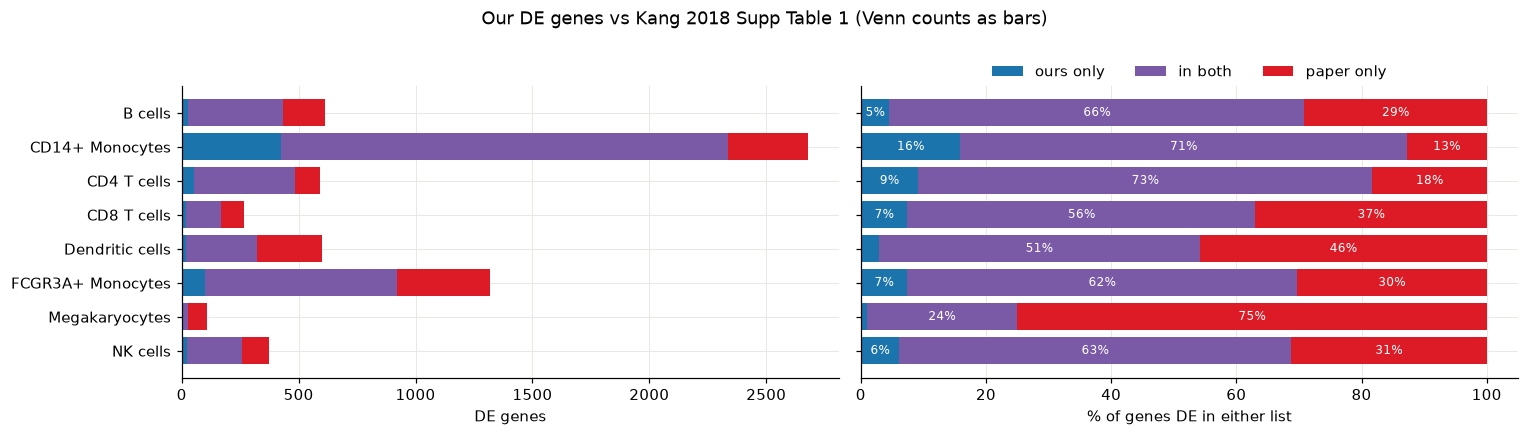

In [4]:
# Excel turned these symbols into dates; mapped by the sheet's Ensembl ID
DATE_FIX = {"ENSG00000184640": "SEPT9", "ENSG00000099785": "MARCH2", "ENSG00000125354": "SEPT6",
            "ENSG00000108387": "SEPT4", "ENSG00000145416": "MARCH1"}
SUFFIX_FIX = {"CLN3": "CLN3.1", "MRPS17": "MRPS17.1", "NDUFB8": "NDUFB8.1", "PSMA2": "PSMA2.1", "TAP2": "TAP2.1"}
rows = []
for s, d in paper.items():
    ct = SHEETS[s]
    sym = d["Unnamed: 0"].map(DATE_FIX).fillna(d["featureData.symbol"]).replace(SUFFIX_FIX)
    p_sign = pd.Series(np.sign(d["log2FoldChange"].to_numpy()), index=sym)
    assert p_sign.index.is_unique and p_sign.index.isin(de["gene"]).all(), ct
    o = de[(de["cell_type"] == ct) & (de["de"] != "none")].set_index("gene")["log2FC"].pipe(np.sign)
    both = o.index.intersection(p_sign.index)
    rows.append({"cell_type": ct, "ours_only": len(o) - len(both), "in_both": len(both),
                 "paper_only": len(p_sign) - len(both), "opposite_sign": int((o[both] != p_sign[both]).sum()),
                 "% paper recovered": round(100 * len(both) / len(p_sign), 1),
                 "% ours in paper": round(100 * len(both) / len(o), 1)})
overlap = pd.DataFrame(rows).set_index("cell_type").loc[counts_table.index]
overlap["V9 (>70%)"] = np.where(overlap["% paper recovered"] > 70, "✓", "✗")
display(counts_table.join(overlap))

venn = overlap[["ours_only", "in_both", "paper_only"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, data, xlabel in [(axes[0], venn, "DE genes"),
                         (axes[1], 100 * venn.div(venn.sum(axis=1), axis=0), "% of genes DE in either list")]:
    left = np.zeros(len(data))
    for col, c in zip(data.columns, ["#1b74ac", "#7a5aa6", "#dd1b26"]):
        bars = ax.barh(data.index, data[col], left=left, color=c, label=col.replace("_", " "))
        if ax is axes[1]:  # label segments wide enough to hold the text
            ax.bar_label(bars, labels=[f"{v:.0f}%" if v >= 4 else "" for v in data[col]],
                         label_type="center", color="white", fontsize=8)
        left += data[col].to_numpy()
    ax.set_xlabel(xlabel)
axes[0].invert_yaxis(); axes[1].legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.12))
fig.suptitle("Our DE genes vs Kang 2018 Supp Table 1 (Venn counts as bars)")
plt.tight_layout()
fig.savefig(ROOT / "figures/m1b_concordance.png", dpi=200, bbox_inches="tight"); plt.show()

## 3. Fits: dispersion trend used, samples, genes tested (every run × cell type)

In [5]:
display(fits[fits["run"] == "main"])
print("fit_type_used over all runs × cell types:")
display(fits.groupby(["fit_type_used"]).size().rename("fits"))
display(fits[fits["fit_type_used"] != "parametric"])

,run,cell_type,fit_type_used,n_samples,n_genes_tested
58,main,B cells,parametric,16,7064
59,main,CD14+ Monocytes,parametric,16,8802
60,main,CD4 T cells,parametric,16,9735
61,main,CD8 T cells,parametric,16,5351
62,main,Dendritic cells,parametric,12,5227
63,main,FCGR3A+ Monocytes,parametric,16,6606
64,main,Megakaryocytes,parametric,8,2688
65,main,NK cells,parametric,16,6108


fit_type_used over all runs × cell types:


fit_type_used
parametric    305
Name: fits, dtype: int64

,run,cell_type,fit_type_used,n_samples,n_genes_tested


## 4. NA p-values and Cook's flags
`cooks_flag` = DESeq2 replaced an outlier count, or results() set the p-value NA by its Cook's filter. Every other NA p-value must be an all-zero gene (the R script stops otherwise).
DESeq2 computes Cook's distances only for samples whose design cell (unique row of the model matrix) holds ≥ 3 samples; in `~ donor + condition` every sample is alone in its cell, so paired runs cannot flag anything.

In [6]:
na = runs.assign(na_p=runs["pvalue"].isna())
na_table = na.groupby(["run", "cell_type"])[["na_p", "cooks_flag"]].sum()
display(na_table.loc[["main", "no_outliers", "unpaired"]].unstack(0))
print("Cook's-flagged genes, all runs:", int(runs["cooks_flag"].sum()))
print("NA p-value genes with any non-zero count, main run:",
      int((de["pvalue"].isna() & (de["baseMean"] > 0)).sum()))

na_p                      cooks_flag                     
run                main no_outliers unpaired       main no_outliers unpaired
cell_type                                                                   
B cells            2362        2599     2362          0           0        9
CD14+ Monocytes    1587        1590     1587          0           0        7
CD4 T cells        1076        1125     1076          0           0        6
CD8 T cells        3054        3323     3054          0           0        5
Dendritic cells    4087        4173     4092          0           0        5
FCGR3A+ Monocytes  2747        2780     2747          0           0       15
Megakaryocytes     6580        6855     6586          0           0        6
NK cells           3045        3164     3045          0           0        8

Cook's-flagged genes, all runs: 61
NA p-value genes with any non-zero count, main run: 0


## 5. Volcano plots (main run, tested genes)
Red: up; blue: down; grey: not DE. Dashed: |log2FC| = 1. y = −log10 q.

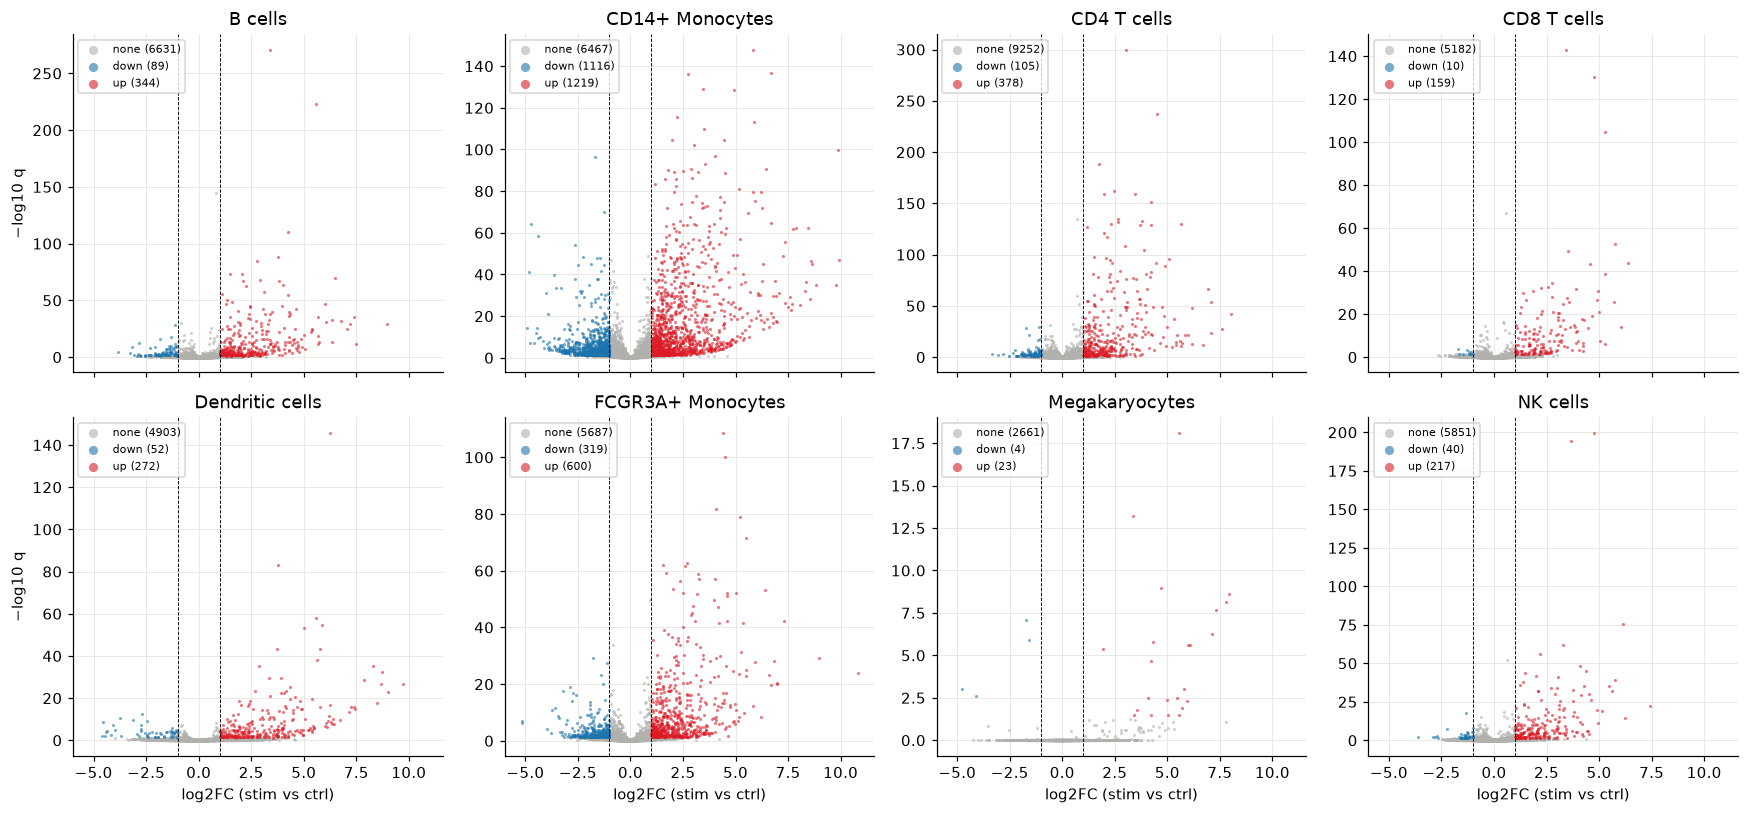

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5), sharex=True)
COLORS = {"up": "#dd1b26", "down": "#1b74ac", "none": "#b0b0ad"}
for ax, ct in zip(axes.flat, CELL_TYPES):
    d = de[(de["cell_type"] == ct) & de["tested"] & de["qvalue"].notna()]
    for call in ["none", "down", "up"]:
        s = d[d["de"] == call]
        ax.scatter(s["log2FC"], -np.log10(s["qvalue"].clip(lower=1e-300)), s=4, c=COLORS[call], alpha=0.6, lw=0,
                   label=f"{call} ({len(s)})")
    ax.axvline(-1, ls="--", c="k", lw=0.6); ax.axvline(1, ls="--", c="k", lw=0.6)
    ax.set_title(ct); ax.legend(fontsize=7, loc="upper left", markerscale=3)
for ax in axes[1]:
    ax.set_xlabel("log2FC (stim vs ctrl)")
for ax in axes[:, 0]:
    ax.set_ylabel("−log10 q")
plt.tight_layout(); plt.show()

## 6. Top 20 DE genes per cell type (main run, by q, then |log2FC|)
CLAUDE.md sanity check: classic ISGs (ISG15, IFIT*, MX1, OAS*, STAT1 …) should dominate. Last row counts ribosomal genes among the top 50 (`ribosomal_mask`, decision D4).

In [8]:
top = {}
ribo50 = {}
for ct in CELL_TYPES:
    d = de[(de["cell_type"] == ct) & (de["de"] != "none")].copy()
    d["abs"] = d["log2FC"].abs()
    d = d.sort_values(["qvalue", "abs"], ascending=[True, False])
    top[ct] = [f"{g} ({'+' if l > 0 else '−'}{abs(l):.1f})" for g, l in zip(d["gene"].head(20), d["log2FC"].head(20))]
    top[ct] += [""] * (20 - len(top[ct]))
    ribo50[ct] = int(ribosomal_mask(d["gene"].head(50)).sum())
top_table = pd.DataFrame(top, index=range(1, 21))
top_table.loc["RPL/RPS in top 50"] = ribo50
display(top_table)

,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,Dendritic cells,FCGR3A+ Monocytes,Megakaryocytes,NK cells
1,ISG20 (+3.4),ISG20 (+5.8),ISG20 (+3.0),ISG20 (+3.4),ISG15 (+6.2),APOBEC3A (+4.4),ISG15 (+5.6),ISG15 (+4.7)
2,ISG15 (+5.6),IL1RN (+6.7),TNFSF10 (+4.5),ISG15 (+4.8),ISG20 (+3.8),ISG20 (+4.5),ISG20 (+3.4),ISG20 (+3.7)
3,LY6E (+4.2),DYNLT1 (+2.8),PSMB9 (+1.7),IFI6 (+5.3),IFI6 (+5.6),TNFSF10 (+4.1),IFI6 (+4.7),IFIT1 (+6.2)
4,IRF7 (+3.8),SSB (+3.4),BST2 (+2.5),IFIT1 (+5.8),IFITM3 (+5.9),IFIT3 (+5.2),IFIT1 (+7.9),TNFSF10 (+3.3)
5,UBE2L6 (+2.8),IFITM2 (+4.9),IRF7 (+3.5),LY6E (+3.5),LY6E (+5.0),IFIT2 (+5.5),IFIT2 (+7.8),PRF1 (+2.2)
6,MYL12A (+1.5),TMSB10 (+2.2),DRAP1 (+2.0),IFIT3 (+6.4),IRF7 (+3.7),OAS1 (+2.7),IFIT3 (+7.3),PLSCR1 (+4.1)
7,PSMB9 (+2.0),NT5C3A (+5.9),MT2A (+4.2),MT2A (+4.6),MX1 (+5.8),MYL12A (+1.5),FTL (−1.7),MX1 (+4.4)
8,TNFSF10 (+6.5),IRF7 (+3.5),SAT1 (+2.7),MX1 (+5.3),OAS1 (+5.6),SSB (+2.6),RSAD2 (+7.1),ANXA1 (+1.5)
9,IFITM2 (+2.9),MYL12A (+2.0),GBP1 (+3.8),SAMD9 (+2.8),CXCL11 (+8.3),TMSB10 (+1.7),FTH1 (−1.6),UBE2L6 (+2.0)
10,EPSTI1 (+3.8),OASL (+4.5),UBE2L6 (+2.7),SAT1 (+2.6),BST2 (+2.9),IRF7 (+3.2),LY6E (+4.3),SAT1 (+3.0)


## 7. DE counts per run (up + down), per cell type
LODO and shuffle columns give min–max over their runs. Table only; interpretation (R1–R3, N1) is M2's.

In [9]:
per_run = runs[runs["de"] != "none"].groupby(["run", "cell_type"]).size()
per_run = per_run.reindex(pd.MultiIndex.from_frame(fits[["run", "cell_type"]]), fill_value=0)
per_run = per_run.rename("n_de").reset_index()
per_run["family"] = per_run["run"].str.replace(r"_.*", "", regex=True).where(
    per_run["run"].str.match(r"^(lodo|shuffle)_"), per_run["run"])


def _range(s):
    return f"{s.min()}–{s.max()} (n={len(s)})"


summary = pd.DataFrame({
    "main": per_run[per_run["family"] == "main"].set_index("cell_type")["n_de"],
    "no_outliers": per_run[per_run["family"] == "no_outliers"].set_index("cell_type")["n_de"],
    "unpaired": per_run[per_run["family"] == "unpaired"].set_index("cell_type")["n_de"],
    "lodo min–max": per_run[per_run["family"] == "lodo"].groupby("cell_type")["n_de"].agg(_range),
    "shuffle min–max": per_run[per_run["family"] == "shuffle"].groupby("cell_type")["n_de"].agg(_range),
})
display(summary)

,main,no_outliers,unpaired,lodo min–max,shuffle min–max
cell_type,,,,,
B cells,433,455,491,340–428 (n=8),0–2 (n=35)
CD14+ Monocytes,2335,2341,2465,2014–2242 (n=8),0–1 (n=35)
CD4 T cells,483,485,481,399–476 (n=8),0–0 (n=35)
CD8 T cells,169,154,168,127–161 (n=8),0–0 (n=35)
Dendritic cells,324,325,472,235–278 (n=6),0–0 (n=10)
FCGR3A+ Monocytes,919,913,1086,700–884 (n=8),0–0 (n=35)
Megakaryocytes,27,23,45,14–21 (n=4),0–0 (n=3)
NK cells,257,247,289,213–241 (n=8),0–0 (n=35)


## 8. Do technical covariates threaten the DE calls? Variance fractions of DE vs non-DE genes

M1a's variance partitioning (section 5 of `m1a_pseudobulk`) shows condition explaining a median of ~0 of each gene's
variance, and the technical covariates (`log n_cells`, `log total_counts`) explaining more. Three things to keep in mind:

1. **The median gene doesn't respond to IFN-β.** Most genes are not DE, so condition's share is ~0 for them. For the
   genes we call DE, condition explains the majority of the variance (median 57–83% per cell type), and the
   technical covariates only ~3–9%.
2. **Donor's share is not really 0.** The covariates are per-sample and almost identical to donor (canonical
   correlation 0.80–0.99, M1a section 6): a big donor contributes many cells and counts to every cell type.
   With two terms carrying the same information, variance partitioning can't split it, and the covariates took it.
   Adding them back (donor + covariates, bottom panel) gives donor's real share: median ~15–34% per gene.
3. **Why this doesn't threaten the DE calls:** `~ donor + condition` compares each donor's stim with their own ctrl,
   so donor-level differences (including `n_cells` and `total_counts`) are removed. Within a donor the covariates
   barely differ between conditions (correlation with condition ≤ 0.19; megakaryocytes 0.31), and size factors
   already correct for depth. Direct evidence: label shuffles give 0–2 DE genes (section 7).

**The plot also shows:** DE genes have *less* technical-covariate and donor variance than non-DE genes (bottom two
panels), and a small tail of DE genes where condition explains < 10% (197 of 4,947, 4%; 105 of them in CD14+
monocytes). Those are either noisy low-count genes (large residual) or genes with big donor differences where the
paired test still finds a consistent within-donor shift. Leave-one-donor-out (R1, in M2) will show whether they hold.

Remaining caveats: megakaryocytes (covariates track condition a little more, 4 donors), and condition = 10x run,
which no model can separate.

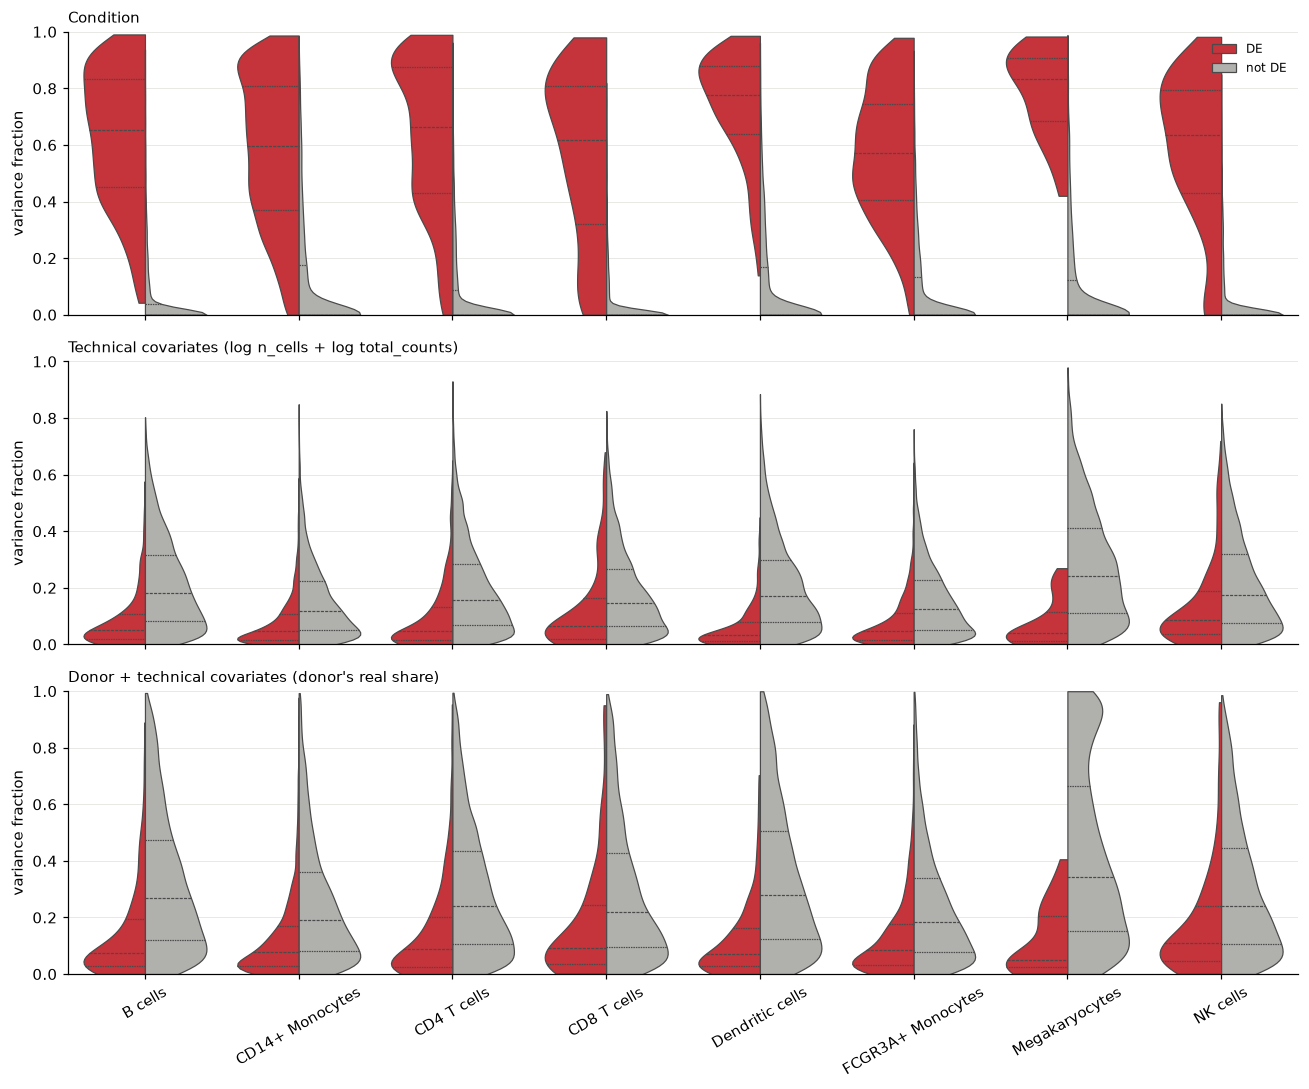

condition  technical covariates  donor + covariates  genes
cell_type         DE status                                                            
B cells           DE             0.652                 0.049               0.074    433
                  not DE         0.000                 0.181               0.267   6631
CD14+ Monocytes   DE             0.598                 0.047               0.079   2335
                  not DE         0.000                 0.117               0.192   6467
CD4 T cells       DE             0.662                 0.048               0.089    483
                  not DE         0.000                 0.156               0.240   9252
CD8 T cells       DE             0.616                 0.065               0.093    169
                  not DE         0.000                 0.145               0.218   5182
Dendritic cells   DE             0.777                 0.033               0.072    324
                  not DE         0.000                 0.171               0.279   4903
FCGR3A+ Monocytes DE             0.571                 0.047               0.085    919
                  not DE         0.000                 0.126               0.182   5687
Megakaryocytes    DE             0.832                 0.042               0.051     27
                  not DE         0.000                 0.243               0.342   2661
NK cells          DE             0.637                 0.088               0.111    257
                  not DE         0.000                 0.174               0.240   5851

In [10]:
import seaborn as sns

vp = pd.read_csv(PROC / "m1a_varpart.csv")
vp = vp.merge(de[["cell_type", "gene", "de"]], on=["cell_type", "gene"], how="left", validate="one_to_one")
assert vp["de"].notna().all(), "every gene in variance partitioning should have a main-run DE call"
vp["DE status"] = np.where(vp["de"] != "none", "DE", "not DE")
vp["technical covariates"] = vp["log_n_cells"] + vp["log_total_counts"]
vp["donor + covariates"] = vp["donor"] + vp["technical covariates"]

panels = [("condition", "Condition"), ("technical covariates", "Technical covariates (log n_cells + log total_counts)"),
          ("donor + covariates", "Donor + technical covariates (donor's real share)")]
fig, axes = plt.subplots(len(panels), 1, figsize=(12, 10), sharex=True)
for ax, (col, title) in zip(axes, panels):
    sns.violinplot(data=vp, x="cell_type", y=col, hue="DE status", hue_order=["DE", "not DE"],
                   palette={"DE": "#dd1b26", "not DE": "#b0b0ac"}, split=True, inner="quart", cut=0,
                   density_norm="width", linewidth=0.8, ax=ax)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_ylabel("variance fraction"); ax.set_xlabel(""); ax.set_ylim(0, 1)
    ax.legend(loc="upper right", fontsize=8, frameon=False) if ax is axes[0] else ax.get_legend().remove()
axes[-1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

table = vp.groupby(["cell_type", "DE status"])[["condition", "technical covariates", "donor + covariates"]].median()
table["genes"] = vp.groupby(["cell_type", "DE status"]).size()
display(table.round(3))